# ICS 3202 Artificial Intelligence: CAT 2

**Project:** Plant disease classification for a mobile app

**Dataset:** PlantVillage (Hugging Face: `mohanty/PlantVillage`)

**Approach:** Supervised learning, classifying images into 38 classes.

**Algorithm:** CNN with transfer learning. The base model is ResNet18 pretrained on ImageNet.

In [ ]:
# Run once. This installs the standard PyTorch build, which includes GPU support on Linux.
%pip install -q torch torchvision datasets huggingface_hub pandas matplotlib pillow scikit-learn tqdm

In [ ]:
import gc
import os
import random
import time
import zipfile
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.models as models
from datasets import load_dataset
from huggingface_hub import hf_hub_download
from PIL import Image
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import StratifiedKFold
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm import tqdm

# Settings used by every model, so comparisons stay fair.
REPO = "mohanty/PlantVillage"
SEED = 42
N_FOLDS = 5
MAX_EPOCHS = 10
PATIENCE = 3                  # stop a fold after this many epochs with no improvement
LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-4           # regularisation that discourages overfitting
BATCH_SIZE = 64
NUM_WORKERS = min(4, os.cpu_count() or 1)   # processes that read and prepare images
RUN_COMPARISON = False        # set to True to train the Question 4 models

# Finished folds and the final model are saved here. Colab's own disk is wiped when a
# session ends, so to keep them, we run these lines and use this folder instead:
from google.colab import drive
drive.mount("/content/drive")
OUTPUT_DIR = "/content/drive/MyDrive/ResNet18_Base"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_GPU = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True   # speeds up training when image sizes stay the same

print("Training device:", torch.cuda.get_device_name(0) if USE_GPU else "CPU")
if not USE_GPU:
    print("WARNING: no GPU found. Full training on a CPU will take more than a day.")

Mounted at /content/drive
Training device: Tesla T4


## 1. Load the data

The dataset is a list of image paths. Each path shows the image type and its class, for example `raw/color/Raspberry___healthy/image.JPG`.

We only use the colour images, since colour helps show disease and phone photos are in colour.

In [ ]:
dataset = load_dataset(REPO, name="default")


def to_dataframe(split):
    """Turn the list of image paths into a table with one column per detail."""
    df = pd.DataFrame({"image_path": list(split["text"])})
    parts = df["image_path"].str.split("/", n=3, expand=True)
    df["configuration"] = parts[1]
    df["class"] = parts[2]
    df[["crop", "condition"]] = df["class"].str.split("___", n=1, expand=True)
    return df


train_all = to_dataframe(dataset["train"])
test_all = to_dataframe(dataset["test"])

# Keep colour images only. The supplied train and test splits are kept as they are.
color_train = train_all[train_all["configuration"] == "color"].reset_index(drop=True)
color_test = test_all[test_all["configuration"] == "color"].reset_index(drop=True)

print("Records in each configuration (train):")
print(train_all["configuration"].value_counts())
print(f"\nColour training images: {len(color_train):,}")
print(f"Colour testing images:  {len(color_test):,}")
print(f"Classes: {color_train['class'].nunique()} | Crops: {color_train['crop'].nunique()}")

del dataset, train_all, test_all   # the full tables are no longer needed

README.md:   0%|          | 0.00/6.47k [00:00<?, ?B/s]

color_train.txt:   0%|          | 0.00/4.15M [00:00<?, ?B/s]

grayscale_train.txt:   0%|          | 0.00/4.28M [00:00<?, ?B/s]

segmented_train.txt:   0%|          | 0.00/4.86M [00:00<?, ?B/s]

color_test.txt:   0%|          | 0.00/1.02M [00:00<?, ?B/s]

grayscale_test.txt:   0%|          | 0.00/1.10M [00:00<?, ?B/s]

segmented_test.txt:   0%|          | 0.00/1.28M [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Records in each configuration (train):
configuration
color        43596
grayscale    43203
segmented    42984
Name: count, dtype: int64

Colour training images: 43,596
Colour testing images:  10,709
Classes: 38 | Crops: 14


## 2. Exploratory Data Analysis

We only explore the training data, so the test set does not affect our decisions.

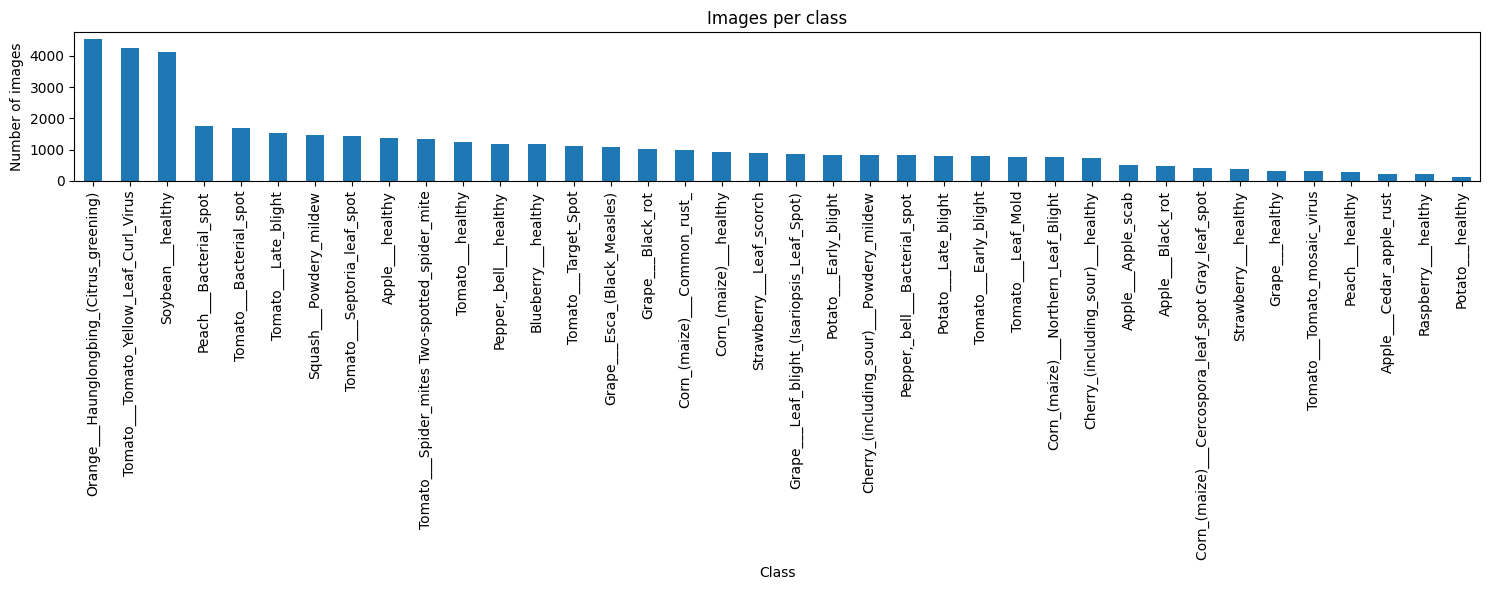

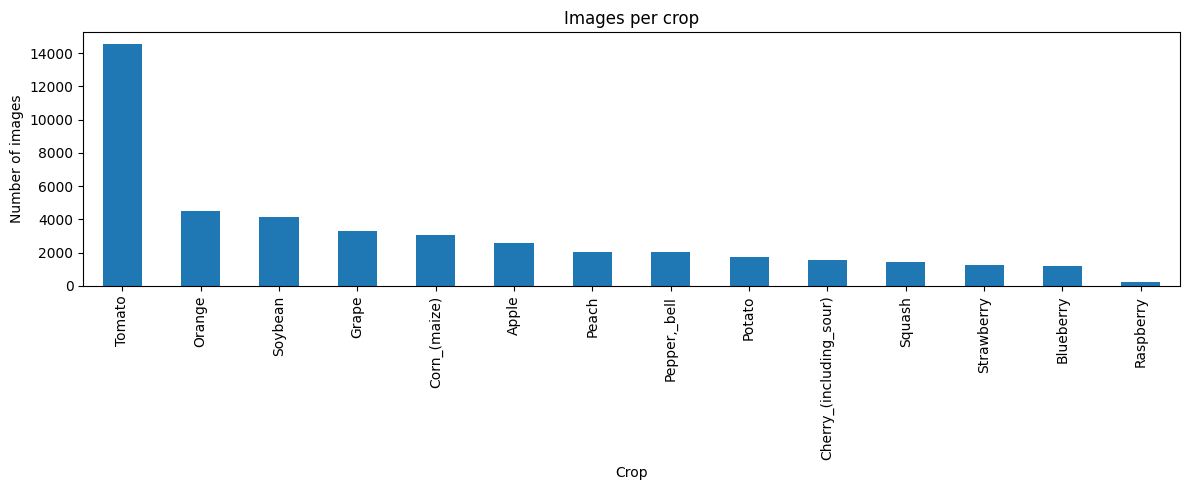

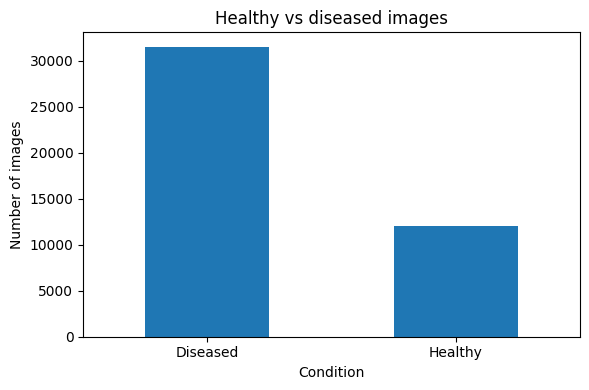

Largest class:  Orange___Haunglongbing_(Citrus_greening) (4,527)
Smallest class: Potato___healthy (120)
Largest crop:   Tomato (14,521)
Smallest crop:  Raspberry (209)
condition
Diseased    72.31
Healthy     27.69


In [ ]:
def bar_chart(counts, title, xlabel, size=(12, 5), rotation=90):
    counts.plot(kind="bar", figsize=size)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel("Number of images")
    plt.xticks(rotation=rotation)
    plt.tight_layout()
    plt.show()


class_counts = color_train["class"].value_counts()
crop_counts = color_train["crop"].value_counts()
health_counts = color_train["condition"].str.lower().eq("healthy").map(
    {True: "Healthy", False: "Diseased"}
).value_counts()

bar_chart(class_counts, "Images per class", "Class", size=(15, 6))
bar_chart(crop_counts, "Images per crop", "Crop")
bar_chart(health_counts, "Healthy vs diseased images", "Condition", size=(6, 4), rotation=0)

print(f"Largest class:  {class_counts.index[0]} ({class_counts.iloc[0]:,})")
print(f"Smallest class: {class_counts.index[-1]} ({class_counts.iloc[-1]:,})")
print(f"Largest crop:   {crop_counts.index[0]} ({crop_counts.iloc[0]:,})")
print(f"Smallest crop:  {crop_counts.index[-1]} ({crop_counts.iloc[-1]:,})")
print((health_counts / len(color_train) * 100).round(2).to_string())

### Observations

1. **Classes are unbalanced.** Orange Huanglongbing has 4,527 images and Potato healthy has 120. We use class weights and macro-F1 because of this.
2. **Crops are unbalanced.** Tomato has 14,521 images and Raspberry has 209.
3. **Most images are diseased.** 72.31% are diseased (31,526) and 27.69% are healthy (12,070).
4. **All colour images are 256 × 256.** This is confirmed in section 3.

## 3. Data cleaning

We check for missing values, repeated paths, images in both train and test, and unreadable files. Unreadable images are removed.

The repeat check only compares paths, so it would miss the same image saved under a different name.

In [ ]:
archive_path = hf_hub_download(repo_id=REPO, filename="data.zip", repo_type="dataset")

print("Missing values:", int(color_train.isnull().sum().sum() + color_test.isnull().sum().sum()))
print("Repeated train paths:", int(color_train["image_path"].duplicated().sum()))
print("Repeated test paths:", int(color_test["image_path"].duplicated().sum()))
print("Paths in both train and test:",
      len(set(color_train["image_path"]) & set(color_test["image_path"])))

# Check every colour image in one pass. Only the file header and contents are verified,
# so images are not fully decoded and this stays quick.
bad_paths, sizes, formats = [], Counter(), Counter()

with zipfile.ZipFile(archive_path) as archive:
    for path in tqdm(pd.concat([color_train, color_test])["image_path"], desc="Checking images"):
        try:
            with archive.open(path) as file:
                image = Image.open(file)
                sizes[image.size] += 1
                formats[image.format] += 1
                image.verify()
        except Exception:
            bad_paths.append(path)

print("Unreadable images:", len(bad_paths))
print("Image sizes:", dict(sizes))
print("Image formats:", dict(formats))

# Final modelling dataset: everything except unreadable images.
color_train = color_train[~color_train["image_path"].isin(bad_paths)].reset_index(drop=True)
color_test = color_test[~color_test["image_path"].isin(bad_paths)].reset_index(drop=True)
print(f"Final dataset: {len(color_train):,} train, {len(color_test):,} test")

data.zip:   0%|          | 0.00/2.18G [00:00<?, ?B/s]

Missing values: 0
Repeated train paths: 0
Repeated test paths: 0
Paths in both train and test: 0


Checking images: 100%|██████████| 54305/54305 [00:09<00:00, 6013.56it/s]

Unreadable images: 0
Image sizes: {(256, 256): 54305}
Image formats: {'JPEG': 54304, 'PNG': 1}
Final dataset: 43,596 train, 10,709 test


## 4. Prepare the images

Images are resized to 224 × 224 and normalised with ImageNet values. Class names are converted to numbers.

Training images also get random flips and rotations so the model sees more variety. Validation and test images do not.

In [ ]:
class_names = sorted(color_train["class"].unique())
class_to_index = {name: index for index, name in enumerate(class_names)}

assert len(class_names) == 38
assert set(color_test["class"]) <= set(class_names), "Test set has an unknown class"

train_paths = color_train["image_path"].to_numpy()
test_paths = color_test["image_path"].to_numpy()
y_train = color_train["class"].map(class_to_index).to_numpy()
y_test = color_test["class"].map(class_to_index).to_numpy()

IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class LeafImages(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths = paths
        self.labels = labels
        self.transform = transform
        self.archive = None   # opened inside each worker, as they cannot share one handle

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        if self.archive is None:
            self.archive = zipfile.ZipFile(archive_path)
        with self.archive.open(self.paths[index]) as file:
            image = Image.open(file).convert("RGB")
        return self.transform(image), int(self.labels[index])


def make_loader(paths, labels, transform, shuffle=False):
    return DataLoader(
        LeafImages(paths, labels, transform), batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=NUM_WORKERS, pin_memory=USE_GPU,
        persistent_workers=NUM_WORKERS > 0,   # keep workers between epochs instead of restarting them
    )


# Check one batch before starting any long training.
check_loader = make_loader(test_paths, y_test, eval_transform)
images, labels = next(iter(check_loader))
assert images.shape == (BATCH_SIZE, 3, 224, 224)
assert labels.min() >= 0 and labels.max() < len(class_names)
print("Image batch shape:", tuple(images.shape))
del check_loader, images, labels

Image batch shape: (64, 3, 224, 224)


## 5. Base model: ResNet18

ResNet18 starts with weights learned from ImageNet. We replace its last layer with one that has 38 outputs, then train the whole network on our leaf images.

- **Class-weighted loss:** mistakes on small classes count for more.
- **AdamW:** the learning rate is 0.0001, and weight decay helps reduce overfitting.
- **Mixed precision:** makes training faster on the GPU.

In [ ]:
def create_resnet18():
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    model.fc = nn.Linear(model.fc.in_features, len(class_names))
    return model


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def create_loss(labels):
    """Give each class a weight, so smaller classes count for more."""
    counts = np.bincount(labels, minlength=len(class_names))
    weights = len(labels) / (len(class_names) * counts)
    return nn.CrossEntropyLoss(weight=torch.tensor(weights, dtype=torch.float32, device=DEVICE))


def train_one_epoch(model, loader, loss_function, optimizer, scaler):
    model.train()
    total_loss = 0.0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=DEVICE.type, enabled=USE_GPU):
            loss = loss_function(model(images), labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_loss += loss.item() * images.size(0)

    return total_loss / len(loader.dataset)


def predict(model, loader):
    model.eval()
    predictions = []

    with torch.inference_mode():   # no training here, so this saves memory and time
        for images, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            with torch.autocast(device_type=DEVICE.type, enabled=USE_GPU):
                predictions.append(model(images).argmax(dim=1).cpu())

    return torch.cat(predictions).numpy()


def free_memory():
    gc.collect()
    if USE_GPU:
        torch.cuda.empty_cache()

## 6. Cross-validation

One split could give a lucky result, so we use 5-fold stratified cross-validation. Each part of the training data takes a turn as the validation set, and every part keeps the same mix of classes. The test set is not used here.

Each fold trains for up to 10 epochs and stops early if macro-F1 does not improve for 3 epochs.

We record accuracy and macro-F1. Macro-F1 treats all classes equally, so it suits our unbalanced data.

In [ ]:
def cross_validate(model_name, create_model):
    """Train a new model on each fold. The seed keeps the folds the same for all models."""
    results_path = os.path.join(OUTPUT_DIR, f"{model_name}_cv.csv")
    results = pd.read_csv(results_path).to_dict("records") if os.path.exists(results_path) else []
    finished_folds = {row["fold"] for row in results}

    splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

    for fold, (train_idx, val_idx) in enumerate(splitter.split(train_paths, y_train), start=1):
        if fold in finished_folds:
            print(f"Fold {fold}: already finished, skipping")
            continue

        set_seed(SEED + fold)
        train_loader = make_loader(train_paths[train_idx], y_train[train_idx], train_transform, shuffle=True)
        val_loader = make_loader(train_paths[val_idx], y_train[val_idx], eval_transform)

        model = create_model().to(DEVICE)
        loss_function = create_loss(y_train[train_idx])
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_GPU)

        best = {"fold": fold, "best_epoch": 0, "accuracy": 0.0, "macro_f1": -1.0}

        for epoch in range(1, MAX_EPOCHS + 1):
            start = time.perf_counter()
            train_loss = train_one_epoch(model, train_loader, loss_function, optimizer, scaler)
            predictions = predict(model, val_loader)
            accuracy = accuracy_score(y_train[val_idx], predictions)
            macro_f1 = f1_score(y_train[val_idx], predictions, average="macro", zero_division=0)

            print(f"Fold {fold} | Epoch {epoch}/{MAX_EPOCHS} | loss {train_loss:.4f} | "
                  f"accuracy {accuracy:.4f} | macro-F1 {macro_f1:.4f} | "
                  f"{time.perf_counter() - start:.0f}s")

            if macro_f1 > best["macro_f1"]:
                best.update(best_epoch=epoch, accuracy=accuracy, macro_f1=macro_f1)
            elif epoch - best["best_epoch"] >= PATIENCE:
                print("Stopping early: no improvement.")
                break

        results.append(best)
        pd.DataFrame(results).to_csv(results_path, index=False)   # save progress after every fold

        del model, optimizer, scaler, loss_function, train_loader, val_loader
        free_memory()

    return pd.DataFrame(results).sort_values("fold").reset_index(drop=True)


base_cv = cross_validate("resnet18", create_resnet18)
display(base_cv.round(4))
print("Mean and standard deviation across folds:")
print(base_cv[["accuracy", "macro_f1"]].agg(["mean", "std"]).round(4))

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 202MB/s]


Fold 1 | Epoch 1/10 | loss 0.3612 | accuracy 0.9857 | macro-F1 0.9805 | 155s
Fold 1 | Epoch 2/10 | loss 0.0540 | accuracy 0.9814 | macro-F1 0.9606 | 146s
Fold 1 | Epoch 3/10 | loss 0.0355 | accuracy 0.9905 | macro-F1 0.9861 | 143s
Fold 1 | Epoch 4/10 | loss 0.0227 | accuracy 0.9908 | macro-F1 0.9853 | 150s
Fold 1 | Epoch 5/10 | loss 0.0219 | accuracy 0.9864 | macro-F1 0.9840 | 143s
Fold 1 | Epoch 6/10 | loss 0.0262 | accuracy 0.9922 | macro-F1 0.9896 | 143s
Fold 1 | Epoch 7/10 | loss 0.0146 | accuracy 0.9928 | macro-F1 0.9906 | 141s
Fold 1 | Epoch 8/10 | loss 0.0238 | accuracy 0.9892 | macro-F1 0.9837 | 143s
Fold 1 | Epoch 9/10 | loss 0.0154 | accuracy 0.9900 | macro-F1 0.9870 | 141s
Fold 1 | Epoch 10/10 | loss 0.0090 | accuracy 0.9961 | macro-F1 0.9946 | 142s
Fold 2 | Epoch 1/10 | loss 0.3589 | accuracy 0.9834 | macro-F1 0.9786 | 146s
Fold 2 | Epoch 2/10 | loss 0.0547 | accuracy 0.9872 | macro-F1 0.9840 | 146s
Fold 2 | Epoch 3/10 | loss 0.0351 | accuracy 0.9919 | macro-F1 0.9897 | 143

,fold,best_epoch,accuracy,macro_f1
0,1,10,0.9961,0.9946
1,2,5,0.9961,0.9940
2,3,10,0.9955,0.9937
3,4,5,0.9952,0.9938
4,5,4,0.9963,0.9946


Mean and standard deviation across folds:
      accuracy  macro_f1
mean    0.9958    0.9941
std     0.0005    0.0004


## 7. Final model and test

We train a new ResNet18 on all the training data, using the average best epoch from cross-validation. We then test it once on the test set and save the model.

Final training epochs: 7
Final model | Epoch 1/7 | loss 0.3034
Final model | Epoch 2/7 | loss 0.0487
Final model | Epoch 3/7 | loss 0.0334
Final model | Epoch 4/7 | loss 0.0219
Final model | Epoch 5/7 | loss 0.0248
Final model | Epoch 6/7 | loss 0.0169
Final model | Epoch 7/7 | loss 0.0219

Test accuracy: 0.9909
Test macro-F1: 0.9893

Five weakest classes:
                                                    precision  recall  \
Tomato___Leaf_Mold                                     0.9048  0.9942   
Tomato___Early_blight                                  0.9949  0.9070   
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot     0.9381  0.9907   
Cherry_(including_sour)___healthy                      0.9389  1.0000   
Corn_(maize)___Northern_Leaf_Blight                    0.9907  0.9636   

                                                    f1-score  support  
Tomato___Leaf_Mold                                    0.9474    172.0  
Tomato___Early_blight                                 0.94

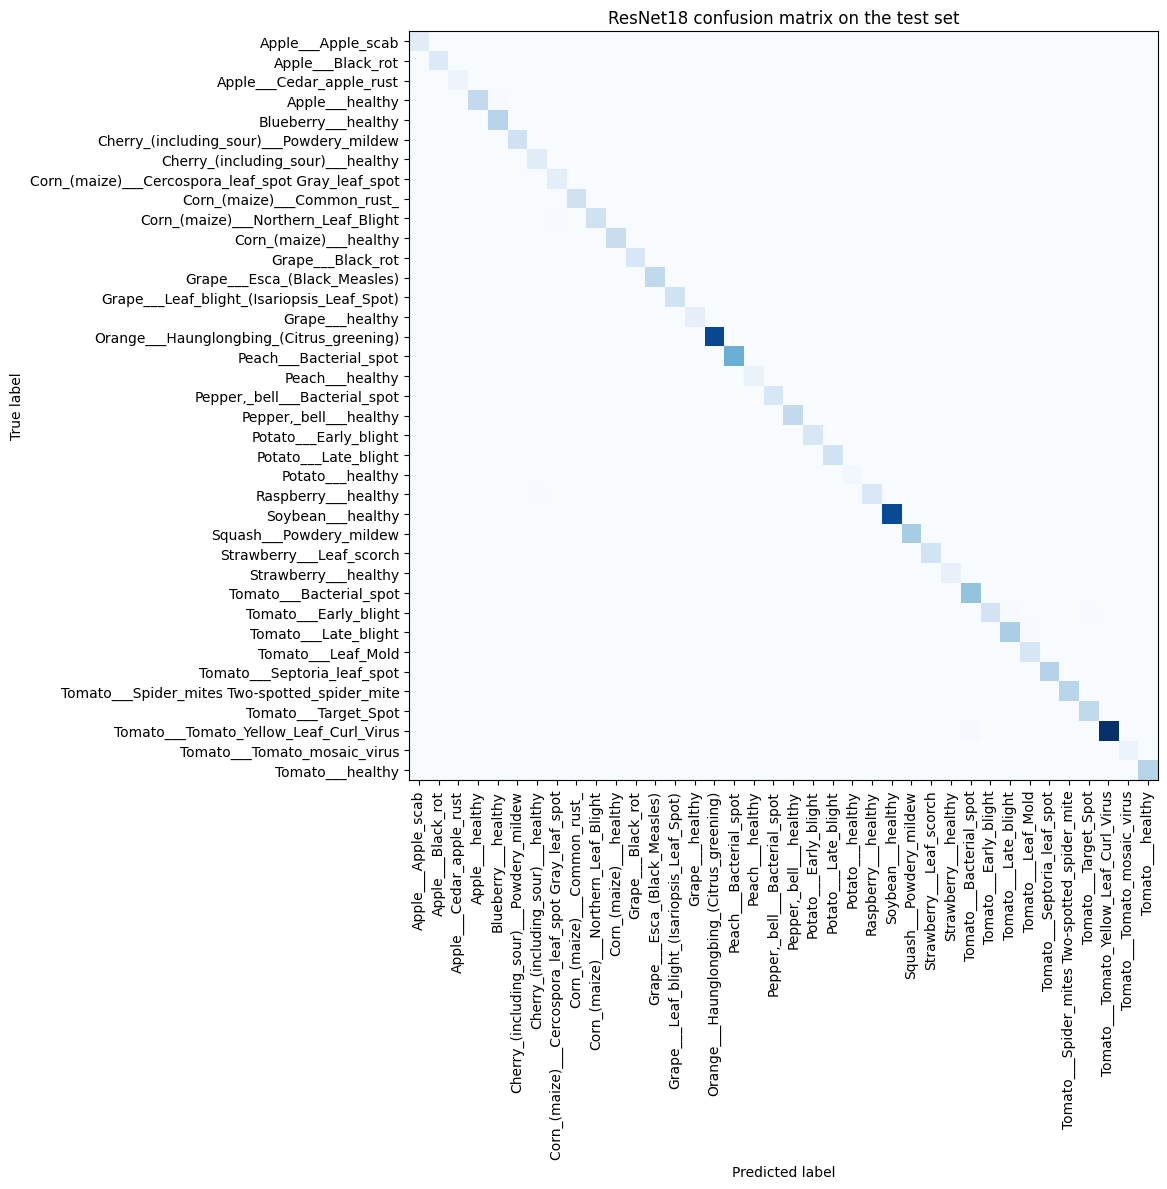

In [ ]:
final_epochs = max(1, int(round(base_cv["best_epoch"].mean())))
print("Final training epochs:", final_epochs)

set_seed(SEED)
train_loader = make_loader(train_paths, y_train, train_transform, shuffle=True)
test_loader = make_loader(test_paths, y_test, eval_transform)

final_model = create_resnet18().to(DEVICE)
loss_function = create_loss(y_train)
optimizer = torch.optim.AdamW(final_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_GPU)

for epoch in range(1, final_epochs + 1):
    train_loss = train_one_epoch(final_model, train_loader, loss_function, optimizer, scaler)
    print(f"Final model | Epoch {epoch}/{final_epochs} | loss {train_loss:.4f}")

torch.save(final_model.state_dict(), os.path.join(OUTPUT_DIR, "resnet18_final.pt"))

test_predictions = predict(final_model, test_loader)

print(f"\nTest accuracy: {accuracy_score(y_test, test_predictions):.4f}")
print(f"Test macro-F1: {f1_score(y_test, test_predictions, average='macro', zero_division=0):.4f}")

label_ids = list(range(len(class_names)))
report = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=label_ids, target_names=class_names,
    output_dict=True, zero_division=0,
)).T

print("\nFive weakest classes:")
print(report.loc[class_names].sort_values("f1-score").head(5).round(4))

figure, axis = plt.subplots(figsize=(14, 12))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, test_predictions, labels=label_ids), display_labels=class_names
).plot(ax=axis, xticks_rotation=90, cmap="Blues", colorbar=False, include_values=False)
plt.title("ResNet18 confusion matrix on the test set")
plt.tight_layout()
plt.show()

del final_model, optimizer, scaler, loss_function, train_loader, test_loader
free_memory()

### Results

Cross-validation gave 99.58% accuracy and 99.41% macro-F1. On the test set, the model got 99.09% accuracy and 98.93% macro-F1. The scores are close, so the model is not just memorising the training data.

The weakest classes were Tomato Leaf Mold (94.74% F1) and Tomato Early Blight (94.89% F1).

## 8. Further validation

To check that ResNet18 was a good choice, we compare it with MobileNetV3-Small, which is built for phones, and EfficientNet-B0, which is small but usually accurate.

A full comparison would use 5 folds and up to 10 epochs per fold, which could take about 6 hours. So we do a quick version with 1 fold and 3 epochs per model. All three models use the same split and settings, and ResNet18 is retrained so the comparison is fair.

We compare accuracy, macro-F1, model size and prediction time on a CPU. The test set is not used.

This is a quick check and not final proof. The models train for less time than in section 6, so these scores should only be compared with each other.



--- ResNet18 ---
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 88.4MB/s]


Epoch 1/3 | loss 0.3501 | 126s
Epoch 2/3 | loss 0.0537 | 119s
Epoch 3/3 | loss 0.0304 | 122s

--- MobileNetV3-Small ---
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 122MB/s]


Epoch 1/3 | loss 0.7957 | 147s
Epoch 2/3 | loss 0.0984 | 122s
Epoch 3/3 | loss 0.0564 | 122s

--- EfficientNet-B0 ---
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 140MB/s]


Epoch 1/3 | loss 0.7530 | 165s
Epoch 2/3 | loss 0.0693 | 134s
Epoch 3/3 | loss 0.0384 | 134s


,model,accuracy,macro_f1,size_mb,cpu_ms_per_image
0,ResNet18,0.9896,0.9856,44.7840,62.3818
1,MobileNetV3-Small,0.9781,0.9678,6.2272,11.1369
2,EfficientNet-B0,0.9409,0.9524,16.2249,35.3099


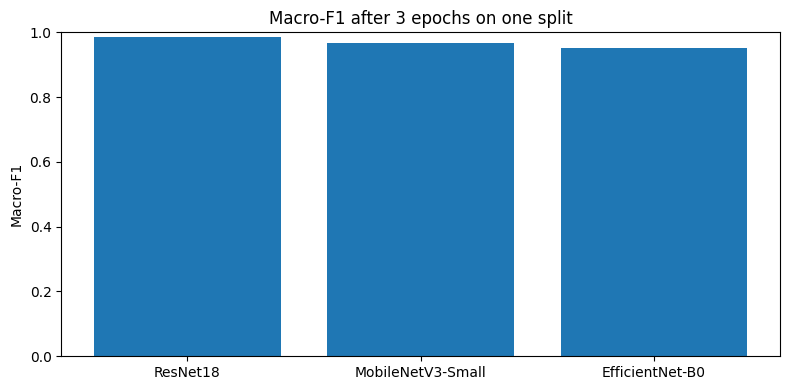

In [ ]:
from sklearn.model_selection import StratifiedKFold

QUICK_EPOCHS = 3


def create_mobilenet_v3():
    model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(class_names))
    return model


def create_efficientnet_b0():
    model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.DEFAULT)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(class_names))
    return model


def measure_model(create_model, repeats=20):
    """Return the model's size in MB and its average CPU time per image in ms."""
    model = create_model().eval()
    size_mb = sum(p.numel() for p in model.parameters()) * 4 / 1e6   # 4 bytes per weight
    image = torch.zeros(1, 3, 224, 224)

    with torch.inference_mode():
        start = time.perf_counter()
        for _ in range(repeats):
            model(image)
        time_ms = (time.perf_counter() - start) / repeats * 1000

    return size_mb, time_ms


candidates = {
    "ResNet18": create_resnet18,
    "MobileNetV3-Small": create_mobilenet_v3,
    "EfficientNet-B0": create_efficientnet_b0,
}

# Use one split for all models: 80% to train and 20% to validate.
splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
train_idx, val_idx = next(splitter.split(train_paths, y_train))

rows = []

for model_name, create_model in candidates.items():
    print(f"\n--- {model_name} ---")
    set_seed(SEED)

    train_loader = make_loader(train_paths[train_idx], y_train[train_idx], train_transform, shuffle=True)
    val_loader = make_loader(train_paths[val_idx], y_train[val_idx], eval_transform)

    model = create_model().to(DEVICE)
    loss_function = create_loss(y_train[train_idx])
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    scaler = torch.amp.GradScaler(DEVICE.type, enabled=USE_GPU)

    for epoch in range(1, QUICK_EPOCHS + 1):
        start = time.perf_counter()
        train_loss = train_one_epoch(model, train_loader, loss_function, optimizer, scaler)
        print(f"Epoch {epoch}/{QUICK_EPOCHS} | loss {train_loss:.4f} | {time.perf_counter() - start:.0f}s")

    predictions = predict(model, val_loader)
    size_mb, time_ms = measure_model(create_model)

    rows.append({
        "model": model_name,
        "accuracy": accuracy_score(y_train[val_idx], predictions),
        "macro_f1": f1_score(y_train[val_idx], predictions, average="macro", zero_division=0),
        "size_mb": size_mb,
        "cpu_ms_per_image": time_ms,
    })

    del model, optimizer, scaler, loss_function, train_loader, val_loader
    free_memory()

comparison = pd.DataFrame(rows)
comparison.to_csv(os.path.join(OUTPUT_DIR, "quick_comparison.csv"), index=False)
display(comparison.round(4))

plt.figure(figsize=(8, 4))
plt.bar(comparison["model"], comparison["macro_f1"])
plt.title(f"Macro-F1 after {QUICK_EPOCHS} epochs on one split")
plt.ylabel("Macro-F1")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Comparison results

| Model | Accuracy | Macro-F1 | Size (MB) | CPU time per image (ms) |
|---|---|---|---|---|
| ResNet18 | 98.96% | 98.56% | 44.8 | 62.4 |
| MobileNetV3-Small | 97.81% | 96.78% | 6.2 | 11.1 |
| EfficientNet-B0 | 94.09% | 95.24% | 16.2 | 35.3 |

ResNet18 had the best accuracy and macro-F1, so we keep it as our base model. MobileNetV3-Small scored about 1.8 points lower on macro-F1, but it is about 7 times smaller and 5.6 times faster, so it is worth considering for the mobile app.

This used only 1 fold and 3 epochs, so the full comparison should be run before making a final choice for the app.
